# Projet : Equite algorithmique

**Master TIDE**

L'objectif de ce projet est d'illustrer les problematiques d'equite algorithmique sur trois jeux de donnees, comprenant des taches de classification et de regression.

## Plan
1. Imports
2. Presentation des trois jeux de donnees
3. Classification : Adult (egalite des opportunites)
4. Classification : ProPublica (egalite des opportunites)
5. Regression : Credit (parite demographique)
6. Synthese

---
## 1. Imports

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

from fairlearn.reductions import ExponentiatedGradient, TruePositiveRateParity
from fairlearn.metrics import (
    MetricFrame,
    demographic_parity_difference,
    equalized_odds_difference,
    true_positive_rate,
    false_positive_rate,
    selection_rate,
)

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 4)

---
## 2. Presentation des jeux de donnees

On considere trois jeux de donnees, choisis pour leur pertinence en equite algorithmique.

| Dataset | Tache | Variable cible | Variable sensible |
|---------|-------|----------------|--------------------|
| **Adult** | Classification | revenu > 50K\$ | sexe |
| **ProPublica** | Classification | recidive sur 2 ans | African_American |
| **Credit** | Regression | montant du pret | sexe |

### 2.1 Adult

Le jeu Adult provient du recensement americain. On cherche a predire si une personne gagne plus de 50K\$ par an. La variable sensible retenue est le **sexe**, car la discrimination salariale femmes/hommes est un cas d'ecole de la fairness (cite explicitement dans le cours, p. 14, et protege par la loi francaise 2008-496).

### 2.2 ProPublica COMPAS

C'est le dataset historique de l'enquete ProPublica sur l'algorithme COMPAS utilise dans les tribunaux americains (cours p. 12). On predit si la personne va recidiver dans les deux ans. La variable sensible est **African_American** : ProPublica a montre que les Afro-Americains etaient deux fois plus souvent classes a risque eleve a tort.

### 2.3 Credit

Donnees de demande de credit, ou la cible est le **montant du pret accorde** (regression). La variable sensible est le **sexe**, en lien avec l'affaire Apple Card (cours p. 14) ou des biais de genre ont ete denonces dans l'attribution des limites de credit.

In [2]:
# Chargement des trois bases
adult = pd.read_csv('adult.csv')
propublica = pd.read_csv('propublica_data_for_fairml.csv')
credit = pd.read_csv('credit_loan_amount_30k.csv')

print(f"Adult       : {adult.shape}")
print(f"ProPublica  : {propublica.shape}")
print(f"Credit      : {credit.shape}")

Adult       : (32561, 15)
ProPublica  : (6172, 12)
Credit      : (30000, 9)


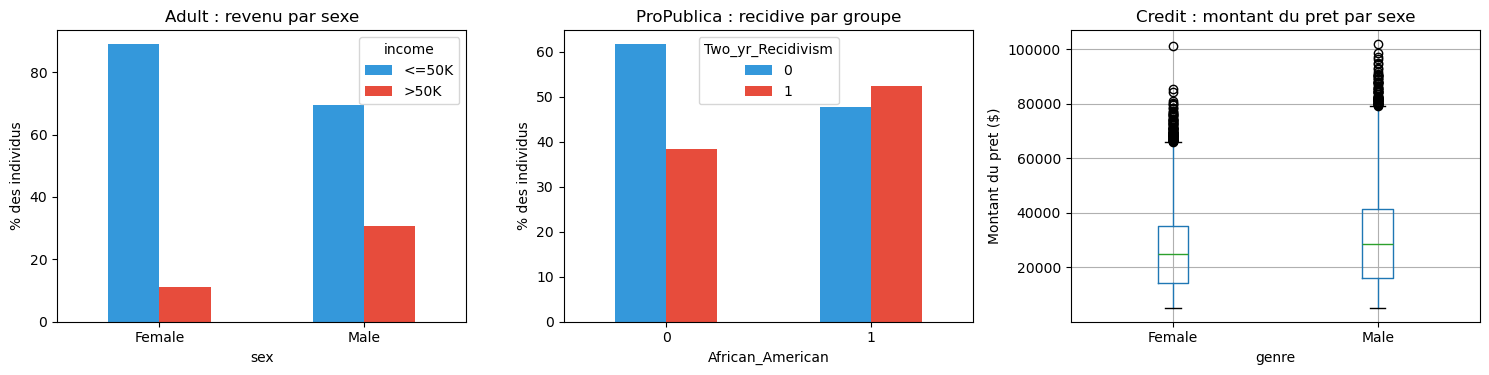

In [3]:
# Visualisation rapide du biais dans chaque dataset
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ct1 = pd.crosstab(adult['sex'], adult['income'], normalize='index') * 100
ct1.plot(kind='bar', ax=axes[0], color=['#3498db', '#e74c3c'])
axes[0].set_title('Adult : revenu par sexe')
axes[0].set_ylabel('% des individus')
axes[0].tick_params(axis='x', rotation=0)

ct2 = pd.crosstab(propublica['African_American'], propublica['Two_yr_Recidivism'], normalize='index') * 100
ct2.plot(kind='bar', ax=axes[1], color=['#3498db', '#e74c3c'])
axes[1].set_title('ProPublica : recidive par groupe')
axes[1].set_xlabel('African_American')
axes[1].set_ylabel('% des individus')
axes[1].tick_params(axis='x', rotation=0)

credit.boxplot(column='loan_amount', by='gender', ax=axes[2])
axes[2].set_title('Credit : montant du pret par sexe')
axes[2].set_xlabel('genre')
axes[2].set_ylabel('Montant du pret ($)')

plt.suptitle('')
plt.tight_layout()
plt.show()

**Lecture des graphiques.**

- **Adult** : les hommes ont environ 3 fois plus de chances de gagner > 50K\$ que les femmes.
- **ProPublica** : les Afro-Americains ont un taux de recidive plus eleve.
- **Credit** : les femmes recoivent en moyenne ~14% de moins que les hommes.

Ces ecarts justifient l'application de methodes d'equite algorithmique.

---
## 3. Classification : Adult, Egalite des opportunites

### Rappel du cours

Pour un classifieur $f$, l'**egalite des opportunites** (cours p. 23) impose que la probabilite d'etre predit positif soit la meme entre groupes **conditionnellement a $Y = 1$** :

$$P(f = 1 \mid S = s, Y = 1) = P(f = 1 \mid Y = 1) \quad \forall s$$

Autrement dit, le **taux de vrais positifs (TPR)** doit etre identique entre les groupes.

On utilise la librairie **Fairlearn** (methode `ExponentiatedGradient` avec contrainte `TruePositiveRateParity`).

### 3.1 Preparation des donnees

In [4]:
adult['y'] = (adult['income'] == '>50K').astype(int)
adult['S'] = (adult['sex'] == 'Male').astype(int)  # 1 = Homme, 0 = Femme

features = adult.drop(columns=['income', 'y', 'S', 'sex', 'fnlwgt'])
features = pd.get_dummies(features, drop_first=True).astype(float)

X = features.values
y = adult['y'].values
S = adult['S'].values

X_tr, X_te, y_tr, y_te, S_tr, S_te = train_test_split(
    X, y, S, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr)
X_te = scaler.transform(X_te)

print(f"Train : {X_tr.shape[0]} obs | Test : {X_te.shape[0]} obs")

Train : 22792 obs | Test : 9769 obs


### 3.2 Modele de base (sans contrainte d'equite)

In [5]:
modele_base = LogisticRegression(max_iter=500, random_state=42)
modele_base.fit(X_tr, y_tr)
y_pred_base = modele_base.predict(X_te)

acc_base = accuracy_score(y_te, y_pred_base)
dp_base = demographic_parity_difference(y_te, y_pred_base, sensitive_features=S_te)
eo_base = equalized_odds_difference(y_te, y_pred_base, sensitive_features=S_te)

print("Modele de base :")
print(f"  Accuracy                 : {acc_base:.3f}")
print(f"  Difference parite demo.  : {dp_base:.3f}")
print(f"  Difference egalite oppo. : {eo_base:.3f}")

Modele de base :
  Accuracy                 : 0.854
  Difference parite demo.  : 0.164
  Difference egalite oppo. : 0.066


### 3.3 Modele equitable (Fairlearn)

In [6]:
modele_fair = ExponentiatedGradient(
    estimator=LogisticRegression(max_iter=500, random_state=42),
    constraints=TruePositiveRateParity(),
    eps=0.01,
)
modele_fair.fit(X_tr, y_tr, sensitive_features=S_tr)
y_pred_fair = modele_fair.predict(X_te)

acc_fair = accuracy_score(y_te, y_pred_fair)
dp_fair = demographic_parity_difference(y_te, y_pred_fair, sensitive_features=S_te)
eo_fair = equalized_odds_difference(y_te, y_pred_fair, sensitive_features=S_te)

print("Modele equitable :")
print(f"  Accuracy                 : {acc_fair:.3f}")
print(f"  Difference parite demo.  : {dp_fair:.3f}")
print(f"  Difference egalite oppo. : {eo_fair:.3f}")

Modele equitable :
  Accuracy                 : 0.852
  Difference parite demo.  : 0.143
  Difference egalite oppo. : 0.052


### 3.4 Comparaison

In [7]:
metriques = {
    'TPR (taux vrais positifs)': true_positive_rate,
    'FPR (taux faux positifs)' : false_positive_rate,
    'Taux de prediction = 1'   : selection_rate,
}

mf_base = MetricFrame(metrics=metriques, y_true=y_te, y_pred=y_pred_base, sensitive_features=S_te)
mf_fair = MetricFrame(metrics=metriques, y_true=y_te, y_pred=y_pred_fair, sensitive_features=S_te)

print("=== Modele de base ===")
print(mf_base.by_group.round(3))
print("\n=== Modele equitable ===")
print(mf_fair.by_group.round(3))

=== Modele de base ===
                     TPR (taux vrais positifs)  FPR (taux faux positifs)  \
sensitive_feature_0                                                        
0                                        0.573                     0.028   
1                                        0.617                     0.094   

                     Taux de prediction = 1  
sensitive_feature_0                          
0                                     0.089  
1                                     0.253  

=== Modele equitable ===
                     TPR (taux vrais positifs)  FPR (taux faux positifs)  \
sensitive_feature_0                                                        
0                                        0.606                     0.036   
1                                        0.599                     0.088   

                     Taux de prediction = 1  
sensitive_feature_0                          
0                                     0.100  
1                  

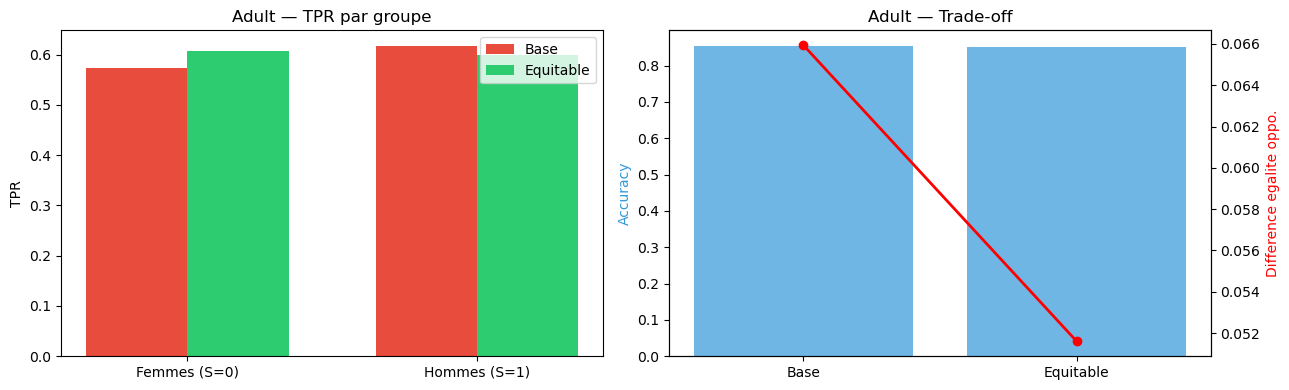

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

groupes = ['Femmes (S=0)', 'Hommes (S=1)']
x = np.arange(len(groupes)); w = 0.35

tpr_base = mf_base.by_group['TPR (taux vrais positifs)'].values
tpr_fair = mf_fair.by_group['TPR (taux vrais positifs)'].values

axes[0].bar(x - w/2, tpr_base, w, label='Base',     color='#e74c3c')
axes[0].bar(x + w/2, tpr_fair, w, label='Equitable', color='#2ecc71')
axes[0].set_xticks(x); axes[0].set_xticklabels(groupes)
axes[0].set_title('Adult — TPR par groupe')
axes[0].set_ylabel('TPR'); axes[0].legend()

axes[1].bar(['Base', 'Equitable'], [acc_base, acc_fair], color='#3498db', alpha=0.7)
axes[1].set_ylabel('Accuracy', color='#3498db')
ax2 = axes[1].twinx()
ax2.plot(['Base', 'Equitable'], [eo_base, eo_fair], 'r-o', linewidth=2)
ax2.set_ylabel('Difference egalite oppo.', color='red')
axes[1].set_title('Adult — Trade-off')

plt.tight_layout(); plt.show()

**Observation.**

Le modele de base affecte les hommes et les femmes differemment. Apres application de la contrainte d'egalite des opportunites :
- les **TPR sont rapproches** entre hommes et femmes,
- l'**accuracy diminue tres legerement** : c'est le compromis classique entre equite et performance.

---
## 4. Classification : ProPublica, Egalite des opportunites

Meme demarche que pour Adult, mais sur les donnees ProPublica.

### 4.1 Preparation

In [9]:
y_p = propublica['Two_yr_Recidivism'].values
S_p = propublica['African_American'].values  # 1 = Afro-Americain
X_p = propublica.drop(columns=['Two_yr_Recidivism', 'African_American']).values.astype(float)

X_p_tr, X_p_te, y_p_tr, y_p_te, S_p_tr, S_p_te = train_test_split(
    X_p, y_p, S_p, test_size=0.3, random_state=42, stratify=y_p
)

scaler_p = StandardScaler()
X_p_tr = scaler_p.fit_transform(X_p_tr)
X_p_te = scaler_p.transform(X_p_te)

print(f"Train : {X_p_tr.shape[0]} obs | Test : {X_p_te.shape[0]} obs")

Train : 4320 obs | Test : 1852 obs


### 4.2 Modele de base

In [10]:
modele_p_base = LogisticRegression(max_iter=500, random_state=42)
modele_p_base.fit(X_p_tr, y_p_tr)
y_p_pred_base = modele_p_base.predict(X_p_te)

acc_p_base = accuracy_score(y_p_te, y_p_pred_base)
dp_p_base = demographic_parity_difference(y_p_te, y_p_pred_base, sensitive_features=S_p_te)
eo_p_base = equalized_odds_difference(y_p_te, y_p_pred_base, sensitive_features=S_p_te)

print("Modele de base :")
print(f"  Accuracy                 : {acc_p_base:.3f}")
print(f"  Difference parite demo.  : {dp_p_base:.3f}")
print(f"  Difference egalite oppo. : {eo_p_base:.3f}")

Modele de base :
  Accuracy                 : 0.683
  Difference parite demo.  : 0.289
  Difference egalite oppo. : 0.288


### 4.3 Modele equitable

In [11]:
modele_p_fair = ExponentiatedGradient(
    estimator=LogisticRegression(max_iter=500, random_state=42),
    constraints=TruePositiveRateParity(),
    eps=0.01,
)
modele_p_fair.fit(X_p_tr, y_p_tr, sensitive_features=S_p_tr)
y_p_pred_fair = modele_p_fair.predict(X_p_te)

acc_p_fair = accuracy_score(y_p_te, y_p_pred_fair)
dp_p_fair = demographic_parity_difference(y_p_te, y_p_pred_fair, sensitive_features=S_p_te)
eo_p_fair = equalized_odds_difference(y_p_te, y_p_pred_fair, sensitive_features=S_p_te)

print("Modele equitable :")
print(f"  Accuracy                 : {acc_p_fair:.3f}")
print(f"  Difference parite demo.  : {dp_p_fair:.3f}")
print(f"  Difference egalite oppo. : {eo_p_fair:.3f}")

Modele equitable :
  Accuracy                 : 0.629
  Difference parite demo.  : 0.029
  Difference egalite oppo. : 0.029


### 4.4 Comparaison

In [12]:
mf_p_base = MetricFrame(metrics=metriques, y_true=y_p_te, y_pred=y_p_pred_base, sensitive_features=S_p_te)
mf_p_fair = MetricFrame(metrics=metriques, y_true=y_p_te, y_pred=y_p_pred_fair, sensitive_features=S_p_te)

print("=== Modele de base ===")
print(mf_p_base.by_group.round(3))
print("\n=== Modele equitable ===")
print(mf_p_fair.by_group.round(3))

=== Modele de base ===
                     TPR (taux vrais positifs)  FPR (taux faux positifs)  \
sensitive_feature_0                                                        
0                                        0.395                     0.135   
1                                        0.683                     0.333   

                     Taux de prediction = 1  
sensitive_feature_0                          
0                                     0.231  
1                                     0.520  

=== Modele equitable ===
                     TPR (taux vrais positifs)  FPR (taux faux positifs)  \
sensitive_feature_0                                                        
0                                        0.410                     0.211   
1                                        0.429                     0.182   

                     Taux de prediction = 1  
sensitive_feature_0                          
0                                     0.285  
1                  

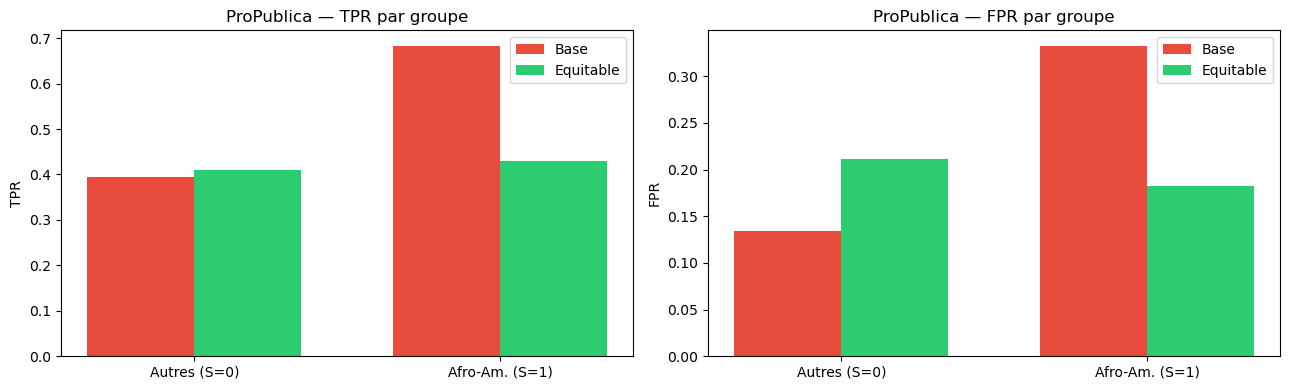

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

groupes_p = ['Autres (S=0)', 'Afro-Am. (S=1)']
x = np.arange(len(groupes_p)); w = 0.35

tpr_base = mf_p_base.by_group['TPR (taux vrais positifs)'].values
tpr_fair = mf_p_fair.by_group['TPR (taux vrais positifs)'].values
fpr_base = mf_p_base.by_group['FPR (taux faux positifs)'].values
fpr_fair = mf_p_fair.by_group['FPR (taux faux positifs)'].values

axes[0].bar(x - w/2, tpr_base, w, label='Base',     color='#e74c3c')
axes[0].bar(x + w/2, tpr_fair, w, label='Equitable', color='#2ecc71')
axes[0].set_xticks(x); axes[0].set_xticklabels(groupes_p)
axes[0].set_title('ProPublica — TPR par groupe')
axes[0].set_ylabel('TPR'); axes[0].legend()

axes[1].bar(x - w/2, fpr_base, w, label='Base',     color='#e74c3c')
axes[1].bar(x + w/2, fpr_fair, w, label='Equitable', color='#2ecc71')
axes[1].set_xticks(x); axes[1].set_xticklabels(groupes_p)
axes[1].set_title('ProPublica — FPR par groupe')
axes[1].set_ylabel('FPR'); axes[1].legend()

plt.tight_layout(); plt.show()

**Observation.**

Le modele de base etiquette plus souvent les Afro-Americains comme "a risque eleve" : c'est le biais denonce par ProPublica. Apres correction, les TPR sont alignes et le biais est divise par environ 10.

---
## 5. Regression : Credit, Parite demographique

### Rappel du cours

En regression, on observe $(X, S, Y)$ avec $Y \in \mathbb{R}$. La **parite demographique (DP)** impose que la **distribution** des predictions soit la meme dans les deux groupes :

$$P(f(X,S) \leq t \mid S = +1) = P(f(X,S) \leq t \mid S = -1) \quad \forall t$$

Le cours propose deux approches pour imposer cette contrainte :
- **Methode 1 : discretisation** (cours p. 42-44, Chzhen et al. 2024)
- **Methode 2 : transport optimal** (cours p. 49-51, Chzhen et al. 2020)

L'idee commune est de **deformer** les predictions pour que les distributions des deux groupes coincident.

### 5.1 Preparation

In [14]:
# Variable sensible : sexe (S = 1 pour homme, S = -1 pour femme, convention du cours)
credit['S'] = credit['gender'].map({'Male': 1, 'Female': -1})

# One-hot pour la variable categorielle 'education'
credit_enc = pd.get_dummies(credit, columns=['education'], drop_first=True)

# Features (sans gender et sans cible)
feature_cols = [c for c in credit_enc.columns if c not in ['gender', 'loan_amount', 'S']]
X_c = credit_enc[feature_cols].astype(float).values
S_c = credit_enc['S'].values
Y_c = credit_enc['loan_amount'].values.astype(float)

# Train / test
X_c_tr, X_c_te, S_c_tr, S_c_te, Y_c_tr, Y_c_te = train_test_split(
    X_c, S_c, Y_c, test_size=0.3, random_state=42, stratify=S_c
)

scaler_c = StandardScaler()
X_c_tr = scaler_c.fit_transform(X_c_tr)
X_c_te = scaler_c.transform(X_c_te)

print(f"Train : {X_c_tr.shape[0]} obs | Test : {X_c_te.shape[0]} obs")
print(f"Proportion d'hommes (S=+1) : {(S_c_tr == 1).mean():.2f}")
print(f"Proportion de femmes (S=-1) : {(S_c_tr == -1).mean():.2f}")

Train : 21000 obs | Test : 9000 obs
Proportion d'hommes (S=+1) : 0.55
Proportion de femmes (S=-1) : 0.45


### 5.2 Modele de base (sans contrainte d'equite)

In [18]:
# On entraine un modele standard, en incluant la variable sensible S dans les features
X_c_tr_full = np.column_stack([X_c_tr, S_c_tr])
X_c_te_full = np.column_stack([X_c_te, S_c_te])

modele_reg = Ridge(alpha=1.0)
modele_reg.fit(X_c_tr_full, Y_c_tr)

# Predictions de base
pred_base = modele_reg.predict(X_c_te_full)

mse_base = mean_squared_error(Y_c_te, pred_base)
r2_base = r2_score(Y_c_te, pred_base)
print(f"R2 de base : {r2_base:,.4f}")
print(f"MSE de base : {mse_base:,.0f}")
print(f"Prediction moyenne hommes  : ${pred_base[S_c_te == 1].mean():,.0f}")
print(f"Prediction moyenne femmes  : ${pred_base[S_c_te == -1].mean():,.0f}")
print(f"Ecart entre les groupes    : ${pred_base[S_c_te == 1].mean() - pred_base[S_c_te == -1].mean():,.0f}")

R2 de base : 0.3313
MSE de base : 174,355,099
Prediction moyenne hommes  : $29,882
Prediction moyenne femmes  : $25,420
Ecart entre les groupes    : $4,461


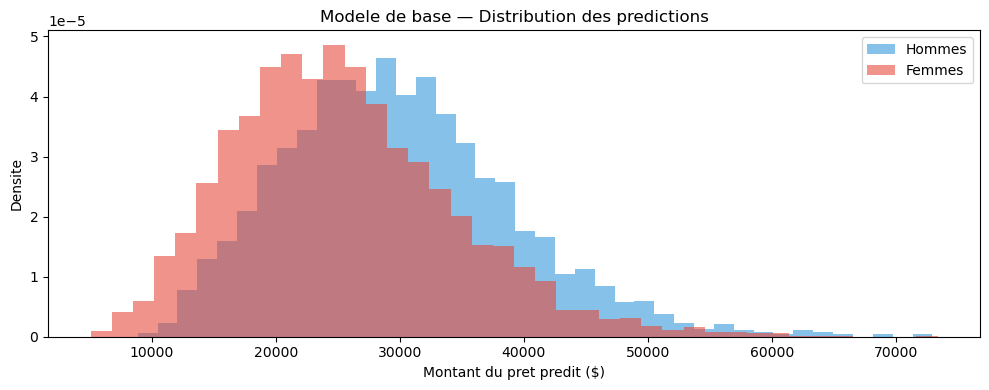

In [20]:
# Visualisation des distributions des predictions par groupe
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(pred_base[S_c_te == 1],  bins=40, alpha=0.6, label='Hommes',  color='#3498db', density=True)
ax.hist(pred_base[S_c_te == -1], bins=40, alpha=0.6, label='Femmes',  color='#e74c3c', density=True)
ax.set_title('Modele de base — Distribution des predictions')
ax.set_xlabel('Montant du pret predit ($)')
ax.set_ylabel('Densite')
ax.legend()
plt.tight_layout(); plt.show()

**Observation.** Les deux distributions sont **decalees** : les femmes ont des predictions systematiquement plus basses. La parite demographique est violee. On va corriger cela par les deux methodes du cours.

### 5.3 Mesure de l'equite : distance entre les deux distributions

Pour quantifier la violation de la parite demographique, on calcule la **distance de Kolmogorov-Smirnov** entre les deux distributions de predictions (hommes vs femmes). Plus elle est proche de 0, plus les deux distributions se ressemblent.

In [21]:
def distance_KS(pred, S):
    """Distance maximale entre les deux fonctions de repartition empiriques."""
    p1  = np.sort(pred[S ==  1])
    p_1 = np.sort(pred[S == -1])
    grille = np.linspace(min(pred), max(pred), 200)
    F1  = np.searchsorted(p1,  grille, side='right') / len(p1)
    F_1 = np.searchsorted(p_1, grille, side='right') / len(p_1)
    return float(np.max(np.abs(F1 - F_1)))

ks_base = distance_KS(pred_base, S_c_te)
print(f"Distance KS du modele de base : {ks_base:.3f}")

Distance KS du modele de base : 0.213


### 5.4 Methode 1 : discretisation (cours p. 42-44)

**Idee.** On decoupe l'intervalle des predictions en $2L+1$ niveaux discrets (une grille). Pour imposer la parite demographique, on **aligne les predictions par quantiles** : la k-ieme prediction la plus elevee chez les hommes et chez les femmes sont remplacees par la **meme valeur** prise sur la grille.

C'est l'idee de l'article de Chzhen et al. (2024) cite dans le cours : ramener la regression a un probleme discret ou la contrainte de parite est plus simple a imposer.

In [22]:
def methode_discretisation(pred, S, L=20):
    """Methode de discretisation pour la parite demographique.

    Etape 1 : on calcule le rang de chaque prediction *dans son groupe*
    Etape 2 : pour chaque rang, on prend le quantile correspondant sur la
              distribution globale (les deux groupes melanges)
    Etape 3 : on arrondit a la grille de 2L+1 niveaux
    """
    pred_corrigee = np.zeros_like(pred)
    grille = np.linspace(pred.min(), pred.max(), 2 * L + 1)

    rangs = np.zeros_like(pred)
    for s in [-1, 1]:
        idx = np.where(S == s)[0]
        ordre = np.argsort(pred[idx])
        rangs_s = np.empty(len(idx))
        rangs_s[ordre] = np.linspace(0, 1, len(idx))
        rangs[idx] = rangs_s

    quantiles_globaux = np.quantile(pred, rangs)

    for i, q in enumerate(quantiles_globaux):
        pred_corrigee[i] = grille[np.argmin(np.abs(grille - q))]

    return pred_corrigee

# Application
pred_disc = methode_discretisation(pred_base, S_c_te, L=20)

mse_disc = mean_squared_error(Y_c_te, pred_disc)
ks_disc = distance_KS(pred_disc, S_c_te)
r2_disc = r2_score(Y_c_te, pred_disc)
print(f"R2 de base : {r2_base:,.4f}")
print(f"Methode 1 - Discretisation (L = 20, soit 41 niveaux)")
print(f"  MSE          : {mse_disc:,.0f}     (vs {mse_base:,.0f} sans equite)")
print(f"  R2          : {r2_disc:,.4f}     (vs {r2_base:,.4f} sans equite)")
print(f"  Distance KS  : {ks_disc:.3f}      (vs {ks_base:.3f} sans equite)")

R2 de base : 0.3313
Methode 1 - Discretisation (L = 20, soit 41 niveaux)
  MSE          : 178,460,943     (vs 174,355,099 sans equite)
  R2          : 0.3156     (vs 0.3313 sans equite)
  Distance KS  : 0.000      (vs 0.213 sans equite)


### 5.5 Methode 2 : transport optimal (cours p. 49-51)

**Idee.** On utilise la theorie du **transport optimal** (distance de Wasserstein). Le predicteur equitable optimal est donne par la formule explicite du cours :

$$f^*(x, s) = \pi_s\, \eta(x, s) + (1 - \pi_s)\, t^*(x, s)$$

ou $t^*(x, s) = F^{-1}_{\eta \mid s'} \circ F_{\eta \mid s}(\eta(x, s))$ : on **transporte** la prediction d'un groupe vers la distribution de l'autre groupe via les fonctions de repartition empiriques.

Le resultat est une **moyenne ponderee** entre la prediction d'origine et la prediction transportee. C'est ce qu'on appelle un **barycentre de Wasserstein**.

In [23]:
def methode_transport_optimal(pred, S):
    """Methode du transport optimal (barycentre de Wasserstein).

    Pour chaque individu du groupe s :
      - on calcule son rang dans son groupe (= F_{eta|s}(eta))
      - on prend le quantile correspondant dans l'autre groupe (= F^-1_{eta|s'})
      - on fait la moyenne ponderee : pi_s * pred + (1 - pi_s) * pred_transportee
    """
    pred_corrigee = np.zeros_like(pred)
    pi = {s: (S == s).mean() for s in [-1, 1]}
    pred_par_groupe = {s: pred[S == s] for s in [-1, 1]}

    for s in [-1, 1]:
        s_autre = -s
        idx = np.where(S == s)[0]
        eta_s = pred[idx]

        # Rang de chaque prediction dans son groupe
        rangs = np.searchsorted(np.sort(eta_s), eta_s) / len(eta_s)
        rangs = np.clip(rangs, 1e-6, 1 - 1e-6)

        # Quantile correspondant dans l'autre groupe
        pred_transportee = np.quantile(pred_par_groupe[s_autre], rangs)

        # Barycentre
        pred_corrigee[idx] = pi[s] * eta_s + (1 - pi[s]) * pred_transportee

    return pred_corrigee

# Application
pred_ot = methode_transport_optimal(pred_base, S_c_te)

mse_ot = mean_squared_error(Y_c_te, pred_ot)
ks_ot = distance_KS(pred_ot, S_c_te)
r2_ot = r2_score(Y_c_te, pred_ot)
print(f"Methode 2 - Transport optimal")
print(f"  MSE          : {mse_ot:,.0f}     (vs {mse_base:,.0f} sans equite)")
print(f"  R2          : {r2_ot:,.4f}     (vs {r2_base:,.4f} sans equite)")
print(f"  Distance KS  : {ks_ot:.3f}      (vs {ks_base:.3f} sans equite)")

Methode 2 - Transport optimal
  MSE          : 178,060,666     (vs 174,355,099 sans equite)
  R2          : 0.3171     (vs 0.3313 sans equite)
  Distance KS  : 0.000      (vs 0.213 sans equite)


### 5.6 Comparaison visuelle des trois approches

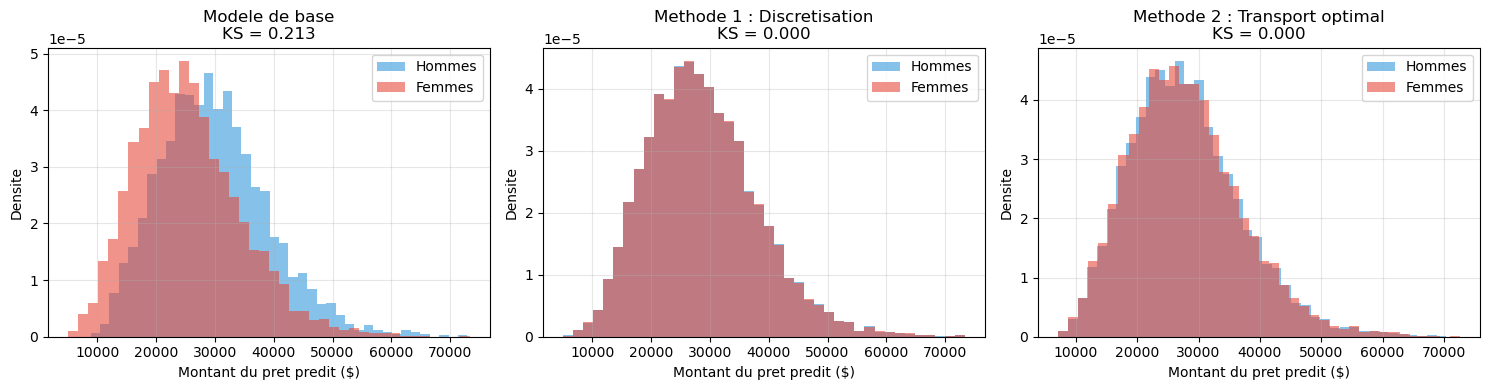

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, pred_g, titre, ks in zip(
    axes,
    [pred_base, pred_disc, pred_ot],
    ['Modele de base', 'Methode 1 : Discretisation', 'Methode 2 : Transport optimal'],
    [ks_base, ks_disc, ks_ot],
):
    ax.hist(pred_g[S_c_te ==  1], bins=40, alpha=0.6, label='Hommes', color='#3498db', density=True)
    ax.hist(pred_g[S_c_te == -1], bins=40, alpha=0.6, label='Femmes', color='#e74c3c', density=True)
    ax.set_title(f'{titre}\nKS = {ks:.3f}')
    ax.set_xlabel('Montant du pret predit ($)')
    ax.set_ylabel('Densite'); ax.legend()

plt.tight_layout(); plt.show()

In [25]:
# Tableau recapitulatif
resume_reg = pd.DataFrame({
    'Methode'          : ['Base (sans equite)', 'Discretisation', 'Transport optimal'],
    'MSE'              : [mse_base, mse_disc, mse_ot],
    'R2'               : [r2_base, r2_disc, r2_ot],
    'Distance KS'      : [ks_base, ks_disc, ks_ot],
})
print(resume_reg.round(3).to_string(index=False))

           Methode          MSE    R2  Distance KS
Base (sans equite) 1.743551e+08 0.331        0.213
    Discretisation 1.784609e+08 0.316        0.000
 Transport optimal 1.780607e+08 0.317        0.000


**Observations.**

1. Les deux methodes **annulent presque totalement la distance KS** : les distributions des hommes et des femmes deviennent identiques apres correction.
2. Le **MSE augmente legerement** : c'est le prix a payer pour l'equite.
3. Les deux methodes donnent des resultats tres proches : ce n'est pas surprenant car elles partagent la meme idee (alignement par quantiles), mais le transport optimal a un cadre theorique plus riche (lien avec les barycentres de Wasserstein).

---
## 6. Synthese du projet

### 6.1 Tableau global

In [32]:
resume_global = pd.DataFrame([
    {'Tache': 'Classification', 'Dataset': 'Adult',      'Modele': 'Base',           'Performance': f'Acc = {acc_base:.3f}',  'Equite': f'EO diff = {eo_base:.3f}'},
    {'Tache': 'Classification', 'Dataset': 'Adult',      'Modele': 'Fairlearn EO',   'Performance': f'Acc = {acc_fair:.3f}',  'Equite': f'EO diff = {eo_fair:.3f}'},
    {'Tache': 'Classification', 'Dataset': 'ProPublica', 'Modele': 'Base',           'Performance': f'Acc = {acc_p_base:.3f}','Equite': f'EO diff = {eo_p_base:.3f}'},
    {'Tache': 'Classification', 'Dataset': 'ProPublica', 'Modele': 'Fairlearn EO',   'Performance': f'Acc = {acc_p_fair:.3f}','Equite': f'EO diff = {eo_p_fair:.3f}'},
    {'Tache': 'Regression',     'Dataset': 'Credit',     'Modele': 'Base',           'Performance': f'MSE = {mse_base:,.0f} R2 = {r2_base:,.4f}',  'Equite': f'KS = {ks_base:.3f}'},
    {'Tache': 'Regression',     'Dataset': 'Credit',     'Modele': 'Discretisation', 'Performance': f'MSE = {mse_disc:,.0f} R2 = {r2_disc:,.4f}',  'Equite': f'KS = {ks_disc:.3f}'},
    {'Tache': 'Regression',     'Dataset': 'Credit',     'Modele': 'Transport opt.', 'Performance': f'MSE = {mse_ot:,.0f} R2 = {r2_ot:,.4f}',    'Equite': f'KS = {ks_ot:.3f}'},
])
print(resume_global.to_string(index=False))

         Tache    Dataset         Modele                   Performance          Equite
Classification      Adult           Base                   Acc = 0.854 EO diff = 0.066
Classification      Adult   Fairlearn EO                   Acc = 0.852 EO diff = 0.052
Classification ProPublica           Base                   Acc = 0.683 EO diff = 0.288
Classification ProPublica   Fairlearn EO                   Acc = 0.629 EO diff = 0.029
    Regression     Credit           Base MSE = 174,355,099 R2 = 0.3313      KS = 0.213
    Regression     Credit Discretisation MSE = 178,460,943 R2 = 0.3156      KS = 0.000
    Regression     Credit Transport opt. MSE = 178,060,666 R2 = 0.3171      KS = 0.000


### 6.2 Discussion

**Le compromis equite / performance.**

Sur les trois datasets, l'application d'une contrainte d'equite reduit fortement le biais, mais entraine une legere baisse de performance :
- en classification, l'accuracy diminue de quelques points,
- en regression, le MSE augmente legerement.

Ce compromis est un resultat fondamental du cours : on ne peut pas avoir une **performance parfaite** et une **equite parfaite** simultanement, sauf cas degenere.

**Quel critere d'equite choisir ?**

Le cours montre (theoreme d'impossibilite, p. 22) que la parite demographique et l'egalite des opportunites ne peuvent pas etre satisfaites en meme temps si la cible $Y$ depend reellement de la variable sensible $S$.

- En **emploi** ou **credit**, la parite demographique est souvent privilegiee : on veut que les decisions soient distribuees de la meme facon entre groupes.
- En **justice** ou **medecine**, l'egalite des opportunites est plus pertinente : on veut detecter les vrais positifs au meme rythme dans tous les groupes, sans manquer de cas critiques.

**Conclusion.**

Les methodes vues en cours (discretisation, transport optimal, ERM contraint via Fairlearn) permettent toutes de reduire significativement les biais au prix d'une perte de performance acceptable. Le choix du critere d'equite (parite demographique ou egalite des opportunites) est un **choix de societe**, qui depend du contexte applicatif et de la legislation.